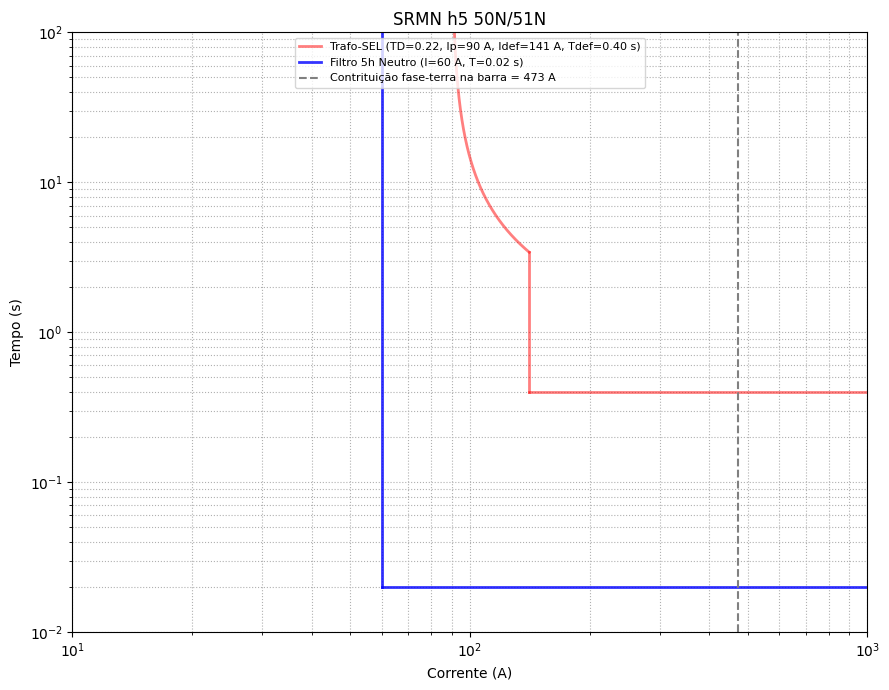

In [1]:
import numpy as np
import matplotlib.pyplot as plt


def iec_inverse_time(I, I_pickup, A, P, time_dial):
    """
    IEC inverse-time equation.
    """
    M = I / I_pickup
    M = np.maximum(M, 1.0001)
    t = time_dial * A / (np.power(M, P) - 1.0)
    return t


def plot_iec_with_definite(curve_dicts,
                           I_min=10.0,
                           I_max=10000.0,
                           n_points=3000,
                           t_max=100.0,
                           axis_and_titles=None):

    fig = plt.figure(figsize=(9, 7))

    for curve in curve_dicts:
        label = curve["label"]
        A = curve["A"]
        P = curve["P"]
        TD = curve["TD"]
        I_pickup = curve["Ipickup"]
        I_def = curve["Idef"]
        T_def = curve["Tdef"]
        color = curve["color"]
        linestyle = curve["linestyle"]
        linewidth = curve["linewidth"]
        alpha = curve.get("alpha", 1.0)

        # -------------------------------------------------
        # Case 1: definite-time only curve (no inverse part)
        # -------------------------------------------------
        if A is None or P is None or TD is None:
            legend_label = (
                f"{label} "
                f"(I={I_pickup:.0f} A, T={T_def:.2f} s)"
            )

            # Vertical segment from T_def up to t_max (protection L)
            plt.loglog(
                [I_pickup, I_pickup],
                [T_def, t_max],
                color=color,
                linestyle=linestyle,
                linewidth=linewidth,
                alpha=alpha
            )

            # Horizontal definite-time segment at T_def
            plt.loglog(
                [I_pickup, I_max],
                [T_def, T_def],
                color=color,
                linestyle=linestyle,
                linewidth=linewidth,
                alpha=alpha,
                label=legend_label
            )
            continue

        # -------------------------------------------------
        # Case 2: inverse-time + definite-time curve
        # -------------------------------------------------

        if I_def <= I_pickup:
            print(
                f"Warning: Idef ({I_def} A) <= Ipickup ({I_pickup} A) "
                f"for curve '{label}'. Curve ignored."
            )
            continue

        legend_label = (
            f"{label} "
            f"(TD={TD:.2f}, Ip={I_pickup:.0f} A, "
            f"Idef={I_def:.0f} A, Tdef={T_def:.2f} s)"
        )

        # Inverse curve segment
        I_start = max(I_min, 1.0001 * I_pickup)
        I_end_inv = min(I_def, I_max)

        if I_end_inv > I_start:
            I_values_inv = np.linspace(I_start, I_end_inv, n_points)
            t_values_inv = iec_inverse_time(I_values_inv, I_pickup, A, P, TD)

            plt.loglog(
                I_values_inv,
                t_values_inv,
                color=color,
                label=legend_label,
                linestyle=linestyle,
                linewidth=linewidth,
                alpha=alpha
            )

        # Time at Idef for the inverse curve
        t_at_Idef = iec_inverse_time(
            np.array([I_def]),
            I_pickup,
            A,
            P,
            TD
        )[0]

        # Draw definite segments only if inside t_max range
        if t_at_Idef <= t_max and T_def <= t_max:

            # Vertical segment at I_def: only from t_at_Idef to T_def
            plt.loglog(
                [I_def, I_def],
                [t_at_Idef, T_def],
                color=color,
                linestyle=linestyle,
                linewidth=linewidth,
                alpha=alpha
            )

            # Horizontal definite-time segment at T_def
            plt.loglog(
                [I_def, I_max],
                [T_def, T_def],
                color=color,
                linestyle=linestyle,
                linewidth=linewidth,
                alpha=alpha
            )

    # Axis labels and title
    if axis_and_titles is not None:
        plt.xlabel(axis_and_titles.get("xlabel", ""))
        plt.ylabel(axis_and_titles.get("ylabel", ""))
        plt.title(axis_and_titles.get("title", ""))

    plt.grid(True, which="both", ls=":")
    plt.xlim(I_min, I_max)
    plt.ylim(0.01, t_max)
    plt.tight_layout()
    return fig


if __name__ == "__main__":
    A_SI = 0.14
    P_SI = 0.02

    curves = [
        {
            "label": "Trafo-SEL",
            "A": A_SI,
            "P": P_SI,
            "TD": 0.22,
            "Ipickup": 90.0,
            "Idef": 141.0,
            "Tdef": 0.4,
            "color": "red",
            "linestyle": "-",
            "linewidth": 2,
            "alpha": 0.5
        },
        {
            "label": "Filtro 5h Neutro",
            "A": None,
            "P": None,
            "TD": None,
            "Ipickup": 60.0,
            "Idef": 60.0,
            "Tdef": 0.02,
            "color": "blue",
            "linestyle": "-",
            "linewidth": 2,
            "alpha": 0.8
        }
    ]

    Icc_max = 473.0

    axis_and_titles = {
        "xlabel": "Corrente (A)",
        "ylabel": "Tempo (s)",
        "title": "SRMN h5 50N/51N"
    }

    fig = plot_iec_with_definite(
        curves,
        axis_and_titles=axis_and_titles,
        I_min=10.0,
        I_max=1000.0,
        t_max=100.0
    )

    plt.loglog(
        [Icc_max, Icc_max],
        [0.01, 100.0],
        color="gray",
        ls="--",
        label=f"Contrituição fase-terra na barra = {Icc_max:.0f} A"
    )

    plt.legend(loc="upper center", fontsize=8)
    fig.show()
